In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.transforms as mpltransforms
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap # Import for custom colors

import seaborn as sns
import os
import datetime
import pickle
import itertools

from scipy.signal import find_peaks
from sklearn.mixture import GaussianMixture
from astropy.stats.circstats import circvar, circmean
from astropy.stats import kuiper
from scipy.stats import pearsonr, ks_2samp
from scipy.stats import entropy

from scipy.stats import ranksums, ttest_ind, f_oneway, false_discovery_control
import statsmodels.regression as sm
from statsmodels.multivariate.multivariate_ols import MultivariateLS
from statannotations.Annotator import Annotator

from pycircstat2.hypothesis import wheeler_watson_test, watson_u2_test
from pycircstat2 import Circular

from sklearn.metrics import accuracy_score, roc_auc_score, average_precision_score, roc_curve
from sklearn.mixture import GaussianMixture

In [3]:
if os.getcwd().endswith('/notebooks/figures'):
    os.chdir('../../')

In [4]:
from src.dataproc import utils, ccutils
from src.model import linearreg, mlmodel
from src.visualize import cycleviz

### Supporting functions

In [5]:
setpairedcolorlist = sns.color_palette('Paired')
setpairedred = setpairedcolorlist[5]
setpairedgreen = setpairedcolorlist[3]
setpairedblue = setpairedcolorlist[1]
setpairedlightblue = setpairedcolorlist[0]


### Stimulation

In [6]:
save_flag = False

In [7]:
fname_format = 'data/RNSdata/NPEhistograms/%s_Histogram_Hourly.csv'
patcodes_path = 'data/RNSdata/Outcome/Hippo_outcomes_postprocessed_2025April08.csv'
longi_patcodes_path = 'data/RNSdata/Outcome/Hippo_longitudinal_outcomes_postprocessed_2025April08.csv'
lsdf_path = 'data/processed/lscycles/plv_postproc_interval/%s.csv'  # interval or not?

outfig_dir = 'output/circpaper_figures/fig03/'
outsupfig_dir = 'output/circpaper_figures/supp/'

In [8]:
outcome_type = 'wtavg_perc_szred'

patcodesdf = pd.read_csv(patcodes_path)

patcodesdf['sz_red'] = patcodesdf[outcome_type].apply(lambda x: -x/100 if x < 0 else 0)
patcodesdf['seizure_rate'] = patcodesdf['baseline_seizure_rate'] * (1 - patcodesdf['sz_red'])
patcodesdf['log_seizure_rate'] = np.log(patcodesdf['seizure_rate'] + (np.exp(-3.5) * (patcodesdf['seizure_rate'] == 0)))
patcodesdf['log_baseline_seizure_rate'] = np.log(patcodesdf['baseline_seizure_rate'])

patient_list = ccutils.final_patient_list()

patoutcome_cols = ['npe_code', 'sz_red', 'log_baseline_seizure_rate', 'log_seizure_rate']

lgpatcodesdf = pd.read_csv(longi_patcodes_path) # longitudinal outcomes

In [9]:
dfdict = {}

npe0041_date_format = "%m/%d/%y %H:%M"

for patient_id in patient_list:
    fname = fname_format %(patient_id)
    if not os.path.exists(fname):
        print(f'{patient_id}: Histogram file doesnt exist.')
        continue
        
    df = pd.read_csv(fname)
    
    if patient_id == 'NPE0041': # update the formatting of time bins for this patient
        df['Region start time'] = df['Region start time'].apply(lambda x: datetime.datetime.strptime(x, npe0041_date_format).isoformat(sep=' '))
    
    df['Local_hour'] = df['Region start time'].apply(lambda x: datetime.datetime.fromisoformat(x).hour)
    df['npe_code'] = patient_id
    # df['Responder_Type'] = patcodesdf.loc[patcodesdf['npe_code']==patient_id].Responder_Type.item()
    df['sz_red'] = patcodesdf.loc[patcodesdf['npe_code']==patient_id].sz_red.item()
    df['RX_norm'] = (df['Episode starts with RX'] - df['Episode starts with RX'].mean()) / df['Episode starts with RX'].std()
    max_hour = df.groupby(by='Local_hour')['Episode starts with RX'].mean().idxmax()
    df['Maxalgn_hour'] = (df['Local_hour'] - max_hour)  % 24
    df['Maxalgn_mid_hour'] = ( df['Maxalgn_hour'] - 12 ) % 24
    
    # time from implantation
    implantdt = datetime.datetime.fromisoformat(patcodesdf.loc[patcodesdf['npe_code']==patient_id]['implant_date'].item())
    utils.tfromstart_days(df, datecol='Region start time', start_date=implantdt)
    ccutils.round_half_year_days(df)
    
    dfdict[patient_id] = df.copy()

In [10]:
MIN_LS_NSAMP = 120   # 120 MAGIC for interval LS models, 0 otherwise
lsdata_cols = ['amp_unnorm_%s', 'amp_norm_%s', 'peakhour_%s', 'fitpower_%s', 'pvalue_%s']


# read the cycle charateristics csv file and store in a dictionary
lsdf_dict = {}

for patient_id in patient_list:
    
    if not os.path.exists(lsdf_path % (patient_id)):
        print(f'{patient_id}: No LS file found. Removing from patient list.')
        continue
    
    lsdf = pd.read_csv(lsdf_path % (patient_id))  # read Ls file
    
    pat_days_list = [int(item.split('_')[-1]) for item in lsdf.columns if ('nsamp' in item)]
    
    # blank out times with samples less than some threshold
    for daynum in pat_days_list:
        if lsdf[f'nsamp_{daynum}'].iloc[0] < MIN_LS_NSAMP:
            pat_lsdata_cols = [item%(daynum) for item in lsdata_cols]
            lsdf[pat_lsdata_cols] = np.NaN
    
    # store the dataframe
    lsdf_dict[patient_id] = lsdf.copy()
    

## Key dataframes

In [11]:
normtype = 'zeroone'  # 'zeroone', 'maxnorm'
lgmscdict = ccutils.mean_stimcounts(dfdict, patient_list, groupby=['dur_halfyr', 'Local_hour'], 
                                    normtype=normtype)

In [12]:
interval_start = 7  # MAGIC; change based on normtype. zeroone=7, maxnorm=5
interval_end = 11

lgaucdf = ccutils.longi_interval_aucdf(lgmscdict, patient_list, interval_start, interval_end, verbose=True)

Dropped entries because stim AUC=0: # 9


In [13]:
feature_list = lsdf_dict[patient_list[0]]['feature'].to_list()
band_list = ['theta', 'alpha', 'beta', 'gamma']
edge_type_list = ['local']  # local FC, long-range FC, both FCs

subfeatdict = ccutils.get_subfeatdict(feature_list, band_list, edge_type_list)

print('Verify the number of features of each type in the dict:')
print([len(subfeatdict[keyval1][keyval2]) for keyval1 in subfeatdict.keys() 
       for keyval2 in subfeatdict[keyval1].keys()])

Verify the number of features of each type in the dict:
[2, 2, 2, 2, 8]


In [14]:
band_list = ['alpha']
edge_type_list = ['local']

## compute the LS amplitude across different feature types for each patient
lgfeatdf = ccutils.create_lgfcccfeat_dataframe(lsdf_dict, patient_list, band_list, edge_type_list, subfeatdict)

# hour at which FC-CC are max in prob for both hemispheres
lgpkhourdf = ccutils.longi_mean_cycle_peakhour(lsdf_dict, patient_list, band_list, 
                                               edge_type_list, subfeatdict)

lgfeatdf = lgfeatdf.merge(lgpkhourdf, on=['npecode', 'band', 'days_from_implant'])

# pair with previous 6-month window observations
lgfeatdf = ccutils.align_curr_previous_fccc(lgfeatdf, pivot_band_into_column=False)

# combine stimulation feature with FC-CC features
lgdf = lgaucdf.merge(lgfeatdf, how='left', left_on=['npecode', 'dur_day'],
                     right_on=['npecode', 'days_from_implant'])
lgdf.dropna(axis=0, inplace=True)  # remove rows with nans

In [15]:
lgaucdf.shape[0], lgfeatdf.shape[0], lgdf.shape[0]

(359, 233, 172)

In [16]:
# combine left and right (cycle 1 and 2) into a single column
fsdf = ccutils.melt_left_right_into_single_column(lgdf)

In [17]:
fsdf.shape

(344, 20)

In [18]:
## effectsize ytick labels
mcoef_ytldict = {'amp_prev': '$A^{c}_{t-6mo}$',
                 'amp_prev_deltasign': r'$\pm$ $A^{c}_{t-6mo}$',
                 'sin_fccc_prev': 'sin($\phi^{c}_{t-6mo}$)', 
                 'cos_fccc_prev': 'cos($\phi^{c}_{t-6mo}$)', 
                 'auc_interval': f'NUS({interval_start}h-{interval_end}h)',
                 'auc_converse': f'NUS({interval_end}-{interval_start}h)',
                 'sin_stim': 'sin($\phi^{s}_{t}$)', 
                 'cos_stim': 'cos($\phi^{s}_{t}$)'}

## color map for effectsize 
escolordict = {1:'tab:blue', -1:'silver'}

### 3A: Distribution of peak hour of FC-CC and stimulation

In [19]:
fccc_peak_hour_list = lgpkhourdf[['cycle1peak_local', 'cycle2peak_local']].dropna().to_numpy().flatten()

# the data is distributed non-uniformly
print(f"Uniformity test: n = {len(fccc_peak_hour_list)}, p = {kuiper(fccc_peak_hour_list/24)[1]}")

Uniformity test: n = 466, p = 5.169599465234107e-06


#### Find cluster centers and boundaries

In [20]:
def number_to_hourmin(nums):
    return ["%d:%0.2d"%(np.floor(num), np.round((num - np.floor(num)) * 60) ) for num in nums]

In [21]:
n_iters = 100

# Transform to 2D coordinates
angular_x = np.cos(np.pi/12 * fccc_peak_hour_list)
angular_y = np.sin(np.pi/12 * fccc_peak_hour_list)
angular_data = np.column_stack([angular_x, angular_y])
fine_grained_angles = np.linspace(start=0, stop=2*np.pi, num=480)

clustermeans = []
transition_hours = []

for _ in range(n_iters):
    # Cluster in 2D space
    gaussmixmod = GaussianMixture(n_components=2).fit(angular_data)
    
    # store clusters
    dayclusindex = 0 if gaussmixmod.means_[0][0] < 0 else 1
    clusmeanday = 12 / np.pi * ( np.arctan(gaussmixmod.means_[dayclusindex][1] / gaussmixmod.means_[dayclusindex][0]) + np.pi ) 
    clusmeannight = 12 / np.pi * ( np.arctan(gaussmixmod.means_[1 - dayclusindex][1] / gaussmixmod.means_[1 - dayclusindex][0]) ) 
    clustermeans.append([clusmeanday, clusmeannight])
    
    # store transition points
    # transition from one cluster to another in probability to compute edge
    fine_grained_probs = gaussmixmod.predict_proba(np.column_stack([np.cos(fine_grained_angles), np.sin(fine_grained_angles)]))
    fine_grained_prob_diff = -1 * np.abs( fine_grained_probs[:,1] - fine_grained_probs[:,0] ) + 1  
    transition_hours.append( fine_grained_angles[find_peaks(fine_grained_prob_diff)[0]] * 12 / np.pi )

# get average
print("Average cluster centers (hr):", number_to_hourmin( np.array(clustermeans).mean(axis=0) ) )
print("Standard deviation of cluster centers (mins):", np.round( np.array(clustermeans).std(axis=0) * 60, 1 ) )
print("\n")
print("Average cluster boundaries (hr):", number_to_hourmin( np.array(transition_hours).mean(axis=0) ) )
print("Standard deviation of cluster boundaries (mins):", np.round( np.array(transition_hours).std(axis=0) * 60, 1 ) )

Average cluster centers (hr): ['15:02', '3:40']
Standard deviation of cluster centers (mins): [3.5 4.1]


Average cluster boundaries (hr): ['9:31', '20:56']
Standard deviation of cluster boundaries (mins): [13.5  3.2]


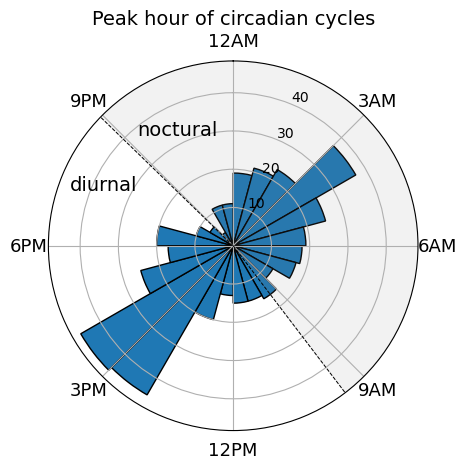

In [22]:
time_low, time_high = np.array(transition_hours).mean(axis=0)   ## define boundaries from data

# Create polar subplot
fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})

# Create histogram
ax.hist(np.pi/12 * fccc_peak_hour_list, bins=np.linspace(0, 2*np.pi, 25), 
        color=setpairedblue, edgecolor='k', alpha=1.0)

ax.axvspan(xmin=(time_high-24) * np.pi/12, 
           xmax=time_low * np.pi/12, color='grey', alpha=0.1)

# cluster boundaries
ax.axvline(x=time_low * np.pi/12, color='k', linestyle='--', linewidth=0.7)
ax.axvline(x=time_high * np.pi/12, color='k', linestyle='--', linewidth=0.7)

# Customize plot
ax.set_theta_zero_location("N")  # Set 0 at the top
ax.set_theta_direction(-1)      # Clockwise direction
ax.set_xticks(ticks=[0, np.pi/4, 2*np.pi/4, 3*np.pi/4, 
                     np.pi, 5*np.pi/4, 6*np.pi/4, 7*np.pi/4], 
              labels=['12AM', '3AM', '6AM', '9AM', 
                      '12PM', '3PM', '6PM', '9PM'], fontsize=13)

ax.text(x=0.35, y=0.8, s='noctural', fontsize=14, color='black', ha='center',
        transform=ax.transAxes)
ax.text(x=0.15, y=0.65, s='diurnal', fontsize=14, color='black', ha='center',
        transform=ax.transAxes)


plt.title('Peak hour of circadian cycles', fontsize=14)

if save_flag:
    plt.savefig(outfig_dir + 'cc_peak_dist.pdf', dpi=300)

plt.show()

### 3B: Clustering of FC-CC peaks

In [23]:
def clus_heatmap_order_score(row):
    num_transitions = row.dropna().diff().abs().sum()   # 
    # clus_init = row[182] if not np.isnan(row[182]) else row[365]  # 0 or 1
    clus_init = row[0.5] if not np.isnan(row[0.5]) else row[1]  # 0 or 1
    if clus_init == 0: order_score = 20 + (10 - num_transitions)
    else: order_score = num_transitions
    return order_score

In [24]:
# use the complete data from lgaucdf
clusdf = lgfeatdf[['npecode', 'days_from_implant', 'cycle1peak_local', 'cycle2peak_local']].copy()
clusdf = clusdf.melt(id_vars=['npecode', 'days_from_implant'], value_vars=['cycle1peak_local', 'cycle2peak_local'], 
                     var_name='cycle', value_name='peaktime')
clusdf['cycle'] = clusdf['cycle'].apply(lambda x: int(x.split('cycle')[1][0]))
clusdf.dropna(axis=0, inplace=True)  # removed NaN columns

# clusdf['fccc_clus'] = clusdf['peaktime'].apply(lambda x: 1 if (x >= 9) & (x < 21) else 0)
clusdf['fccc_clus'] = clusdf['peaktime'].apply(lambda x: 1 if (x >= time_low) & (x < time_high) else 0)

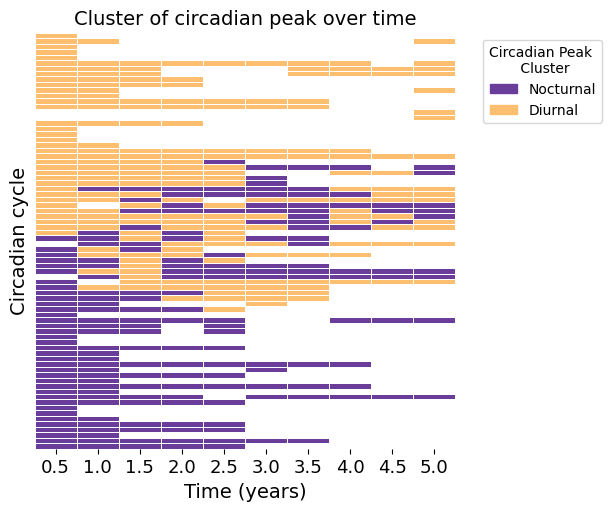

In [25]:
clusdf['yrs_from_implant'] = clusdf['days_from_implant'].apply(lambda x: np.round(x/365, 1))

clushm = clusdf.loc[clusdf['days_from_implant'] <= 1825].pivot(index=['npecode', 'cycle'], columns=['yrs_from_implant'], values='fccc_clus')
clushm['row_order_score'] = clushm.apply(lambda x: clus_heatmap_order_score(x), axis=1)
clushm.sort_values(by='row_order_score', inplace=True)
clushm.drop(columns=['row_order_score'], inplace=True)
clushm.reset_index(drop=True, inplace=True)


# --- Custom Colormap Definition ---
custom_colors = [setpairedcolorlist[9], setpairedcolorlist[6]]
custom_cmap = ListedColormap(custom_colors)

fig,ax = plt.subplots(1,1,figsize=(6,5), layout='constrained')
sns.heatmap(clushm, ax=ax, cmap=custom_cmap, linewidth=0.5, cbar=False)
plt.xlabel('Time (years)', fontsize=14)
plt.ylabel('Circadian cycle', fontsize=14)
plt.title('Cluster of circadian peak over time', fontsize=14)
plt.yticks(ticks=[])
plt.tick_params(labelsize=13)

# custom legend
color_0 = custom_cmap(0.0)  # Color for value 0 (Night)
color_1 = custom_cmap(1.0)  # Color for value 1 (Day)

# 2. Create the legend patches (colored squares)
patch_night = mpatches.Patch(color=color_0, label='Nocturnal')
patch_day = mpatches.Patch(color=color_1, label='Diurnal')

# 3. Add the legend to the Axes
legend = ax.legend(
    handles=[patch_night, patch_day],
    loc='upper left',  # Position the legend
    bbox_to_anchor=(1.05, 1), # Place the legend outside the plot area
    title="Circadian Peak \n Cluster"
)
legend.get_title().set_ha('center')

if save_flag:
    plt.savefig(outfig_dir + 'cc_transitions_per_hemi.pdf', dpi=300)

plt.show()

### Supplement: Heatmap for entire duration

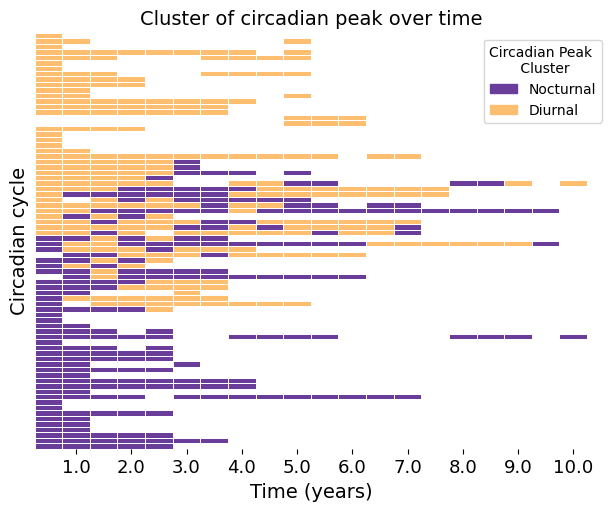

In [26]:
clushm = clusdf.loc[clusdf['days_from_implant'] <= 3650].pivot(index=['npecode', 'cycle'], columns=['yrs_from_implant'], values='fccc_clus')
clushm['row_order_score'] = clushm.apply(lambda x: clus_heatmap_order_score(x), axis=1)
clushm.sort_values(by='row_order_score', inplace=True)
clushm.drop(columns=['row_order_score'], inplace=True)
clushm.reset_index(drop=True, inplace=True)


# --- Custom Colormap Definition ---
custom_colors = [setpairedcolorlist[9], setpairedcolorlist[6]]
custom_cmap = ListedColormap(custom_colors)

fig,ax = plt.subplots(1,1,figsize=(6,5), layout='constrained')
sns.heatmap(clushm, ax=ax, cmap=custom_cmap, linewidth=0.5, cbar=False)
plt.xlabel('Time (years)', fontsize=14)
plt.ylabel('Circadian cycle', fontsize=14)
plt.title('Cluster of circadian peak over time', fontsize=14)
plt.yticks(ticks=[])
plt.xticks(ticks=np.arange(1.5, 20, 2))
plt.tick_params(labelsize=13)

# custom legend
color_0 = custom_cmap(0.0)  # Color for value 0 (Night)
color_1 = custom_cmap(1.0)  # Color for value 1 (Day)

# 2. Create the legend patches (colored squares)
patch_night = mpatches.Patch(color=color_0, label='Nocturnal')
patch_day = mpatches.Patch(color=color_1, label='Diurnal')

# 3. Add the legend to the Axes
legend = ax.legend(
    handles=[patch_night, patch_day],
    loc='upper left',  # Position the legend
    bbox_to_anchor=(0.8, 1), # Place the legend outside the plot area
    title="Circadian Peak \n Cluster"
)
legend.get_title().set_ha('center')

if save_flag:
    plt.savefig(outsupfig_dir + 'cluster_cc_transitions_per_hemi_allyears.pdf', dpi=300)

plt.show()

### Transition probability between clusters

In [27]:
# include all the days so that consecutive events can be counted
clusallentdf = pd.DataFrame(itertools.product(patient_list, [1,2], sorted(clusdf['days_from_implant'].unique()))) 
clusallentdf.rename(columns = {0:'npecode', 1:'cycle', 2:'days_from_implant'}, inplace=True)

In [28]:
clusallentdf = clusallentdf.merge(clusdf, how='left', on=['npecode', 'cycle', 'days_from_implant'])

In [29]:
transdf_1 = pd.DataFrame({})
transdf_1['clus_curr'] = clusallentdf.loc[clusallentdf['cycle']==1]['fccc_clus']
transdf_1['clus_next'] = clusallentdf.loc[clusallentdf['cycle']==1].shift(-1)['fccc_clus']
transdf_1.insert(0, 'cycle', 1)

transdf_2 = pd.DataFrame({})
transdf_2['clus_curr'] = clusallentdf.loc[clusallentdf['cycle']==2]['fccc_clus']
transdf_2['clus_next'] = clusallentdf.loc[clusallentdf['cycle']==2].shift(-1)['fccc_clus']
transdf_2.insert(0, 'cycle', 2)

# combine transitions from cycle 1 an cycle 2
transdf = pd.concat((transdf_1, transdf_2), axis=0, ignore_index=True)

# only keep the transitions with curr and next measured
transdf.dropna(axis=0, how='any', inplace=True)

In [30]:
transdf['trans'] = transdf.apply(lambda x: '%d-%d'%(x['clus_curr'], x['clus_next']), axis=1)

In [31]:
transsr = transdf['trans'].value_counts()
transsr = transsr.reset_index()
transsr['curr'] = transsr['trans'].apply(lambda x: int(x.split('-')[0]))
transsr['next'] = transsr['trans'].apply(lambda x: int(x.split('-')[1]))
transsr['total'] = transsr.groupby(by='curr')['count'].transform('sum')
transsr['prob'] = transsr['count'] / transsr['total']

In [32]:
transsr['name'] = transsr['trans'].apply(lambda x: {'1-1':'day-day', '1-0':'day-night', '0-1':'night-day', '0-0':'night-night'}[x])

In [33]:
transsr

,trans,count,curr,next,total,prob,name
0,1-1,161,1,1,194,0.829897,day-day
1,0-0,144,0,0,176,0.818182,night-night
2,1-0,33,1,0,194,0.170103,day-night
3,0-1,32,0,1,176,0.181818,night-day


### Supplement: Distribution of change in hour of peak

In [34]:
# cluster of FC-CC based on peaktime
fsdf['clus_curr'] = fsdf['peaktime'].apply(lambda x: 'day' if (x >= time_low) & (x < time_high) else 'night')
fsdf['clus_prev'] = fsdf['peaktime_prev'].apply(lambda x: 'day' if (x >= time_low) & (x < time_high) else 'night')

# type of transition
fsdf['trans'] =  fsdf.apply(lambda x: '%s-%s' % (x['clus_prev'], x['clus_curr']), axis=1) 
fsdf['trans_type'] =  fsdf.apply(lambda x: 'same' if (x['clus_prev'] == x['clus_curr']) else 'other', axis=1) 

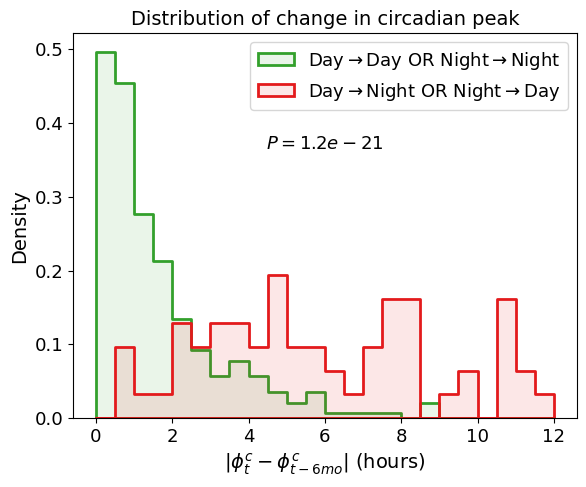

In [35]:
kstestres = ks_2samp(fsdf.loc[fsdf['trans_type']=='same']['ffprev_gap'], 
                     fsdf.loc[fsdf['trans_type']=='other']['ffprev_gap'])

fig, ax = plt.subplots(1, 1, figsize=(6.5,5))
sns.histplot(data=fsdf.loc[fsdf['trans_type']=='same'], x='ffprev_gap', bins=np.linspace(0,12,num=25), stat='density', 
            linewidth=2, fill=True, alpha=0.1, ax=ax, label='same', element='step', color=setpairedgreen)
sns.histplot(data=fsdf.loc[fsdf['trans_type']=='other'], x='ffprev_gap', bins=np.linspace(0,12,num=25), stat='density', 
            linewidth=2, fill=True, alpha=0.1, ax=ax, label='other', element='step', color=setpairedred)

ax.text(x=0.5, y=0.7, s='$P=%0.1e$'%(kstestres.pvalue), transform=ax.transAxes, ha='center', fontsize=13)

plt.xlabel('$|\phi^{c}_{t} - \phi^{c}_{t-6mo} |$ (hours)', fontsize=14)
plt.ylabel('Density', fontsize=14)
plt.title('Distribution of change in circadian peak', fontsize=14)
plt.tick_params(labelsize=13)

plt.legend()
legend = ax.get_legend()
leghand = legend.legend_handles 
legtexts = legend.texts
rtleglabs = [{'same':r'Day$\rightarrow$Day OR Night$\rightarrow$Night', 'other':r'Day$\rightarrow$Night OR Night$\rightarrow$Day'}[item.get_text()] for item in legtexts]
ax.legend(leghand, rtleglabs, fontsize=13)

if save_flag:
    plt.savefig(outsupfig_dir + 'cluster_peak_delta_magnitude.pdf', dpi=300)

plt.show()

In [36]:
print(fsdf.loc[fsdf['trans_type']=='same']['ffprev_gap'].mean(), '$\pm$', fsdf.loc[fsdf['trans_type']=='same']['ffprev_gap'].std())
print(fsdf.loc[fsdf['trans_type']=='other']['ffprev_gap'].mean(), '$\pm$', fsdf.loc[fsdf['trans_type']=='other']['ffprev_gap'].std())

1.6558662378020215 $\pm$ 1.6690927725625333
5.840221217927404 $\pm$ 3.0213033739309036


### 3D: Relationship between FC amplitude and transition type

In [37]:
# transition type labels for machine learning
fsdf['trans_type_int'] = fsdf['trans_type'].apply(lambda x: {'same':0, 'other':1}[x])

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

0 vs. 1: P = 4.8e-06 (n1=282 vs n2=62)


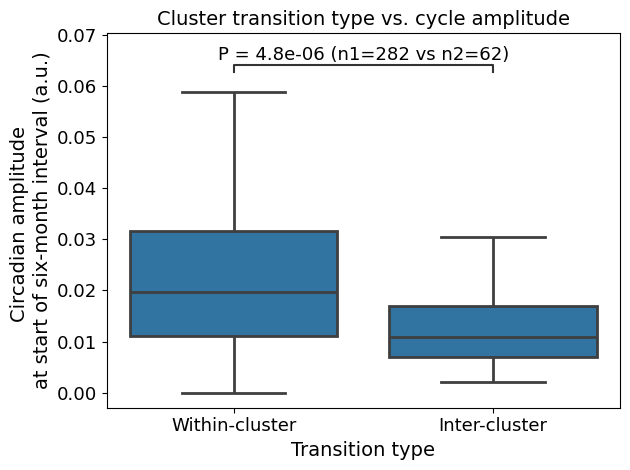

In [38]:
boxdf = fsdf.copy()

boxorder = [0, 1]
boxtickdict = {0: 'Within-cluster', 1:'Inter-cluster'}
boxpairs = [(0, 1)]

ax = sns.boxplot(data=boxdf, x='trans_type_int', y='amp_prev', order=boxorder, 
                 showfliers=False, linewidth=2, color=setpairedblue)  # boxes
# sns.stripplot(data=boxdf, x='trans_type_int', y='amp_prev', ax=ax, color='k', size=3) # data points

ax.set_xlabel('Transition type', fontsize=14)
ax.set_ylabel('Circadian amplitude \nat start of six-month interval (a.u.)', fontsize=14)
ax.set_title('Cluster transition type vs. cycle amplitude', fontsize=14)

ax.set_xticks(ticks=[0,1], labels=[boxtickdict[key] for key in boxorder], fontsize=13)
ax.tick_params(labelsize=13)


n_counts = boxdf.groupby('trans_type_int')['amp_prev'].count()

annotator = Annotator(ax, boxpairs, data=boxdf, x='trans_type_int', y='amp_prev', order=boxorder)
annotator.configure(test='t-test_ind', loc='inside', fontsize=13)
annotator.apply_test()

pval = annotator.annotations[0].data.pvalue
n1 = n_counts[boxpairs[0][0]]
n2 = n_counts[boxpairs[0][1]]

custom_label = f"P = {pval:.1e} (n1={n1} vs n2={n2})"
annotator.set_custom_annotations([custom_label])
annotator.annotate()

# annotator.configure(test='t-test_ind', text_format='full', show_test_name=False, loc='inside', 
#                     fontsize=13, p_capitalized=True)
# annotator.apply_and_annotate()

plt.tight_layout()

if save_flag:
    plt.savefig(outfig_dir + 'transition_vs_amplitude_boxplot.pdf', dpi=300)

plt.show()

In [39]:
print(boxdf['trans_type'].value_counts())
print(ttest_ind(boxdf.loc[boxdf['trans_type']=='same']['amp_prev'].values, 
          boxdf.loc[boxdf['trans_type']=='other']['amp_prev'].values))

trans_type
same     282
other     62
Name: count, dtype: int64
TtestResult(statistic=4.645663612189752, pvalue=4.843624336580214e-06, df=342.0)


### 3E: Machine learning model

In [40]:
regfeat_cols = ['amp_prev', 'sin_fccc_prev', 'cos_fccc_prev']

yvar = 'trans_type_int'

final_mlfeats = mlmodel.recursive_feature_elimination(regdf=fsdf, full_feature_list=regfeat_cols, yvar=yvar, 
                                                  cv_folds_list=patient_list, cv_var='npecode', remove_outliers=False)
print('!!!!!!!! Final feature list:', final_mlfeats, '!!!!!!!!!!!!!')

Outliers NOT removed. Num entries: 344.
Cross-validation complete.
Fractional feature importance of each feature:
 amp_prev         0.858484
sin_fccc_prev    0.023269
cos_fccc_prev    0.118247
dtype: object
Outliers NOT removed. Num entries: 344.


Cross-validation complete.
Fractional feature importance of each feature:
 amp_prev         0.874179
cos_fccc_prev    0.125821
dtype: object
!!!!!!!! Final feature list: ['amp_prev', 'cos_fccc_prev'] !!!!!!!!!!!!!


In [41]:
### ML model
mlpreddf, mlmoddict = mlmodel.cross_validation(regdf=fsdf, 
                                               regfeat_cols=final_mlfeats, yvar=yvar, 
                                               cv_folds_list=patient_list, cv_var='npecode', 
                                               remove_outliers=False)

Outliers NOT removed. Num entries: 344.


Cross-validation complete.


In [42]:
roc_auc_score(mlpreddf['gt'], mlpreddf['modpred']), average_precision_score(mlpreddf['gt'], mlpreddf['modpred'])

(0.6893731411576298, 0.26475033367689477)

In [43]:
roc_fpr, roc_tpr, roc_thresh = roc_curve(mlpreddf['gt'], mlpreddf['modpred'])
rocval = roc_auc_score(mlpreddf['gt'], mlpreddf['modpred'])

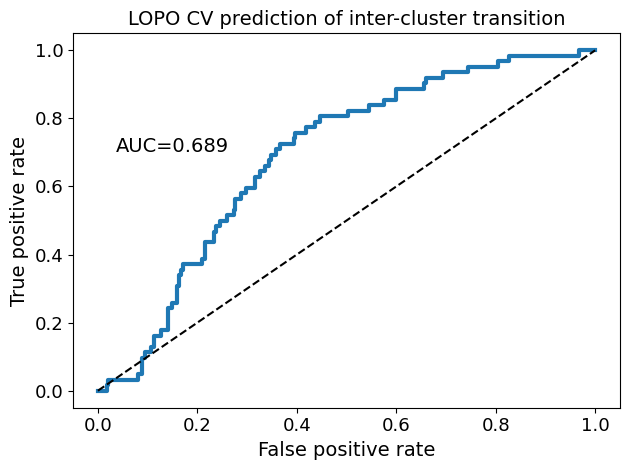

In [44]:
plt.plot(roc_fpr, roc_tpr, linewidth=3, color=setpairedblue)
plt.plot(np.linspace(0,1,30), np.linspace(0,1,30), linestyle='--', color='k')
plt.text(x=0.15, y=0.7, s='AUC=%0.3f'%(rocval), ha='center', fontsize=14)

plt.xlabel('False positive rate', fontsize=14)
plt.ylabel('True positive rate', fontsize=14)
plt.title('LOPO CV prediction of inter-cluster transition', fontsize=14)
plt.tick_params(labelsize=13)

plt.tight_layout()

if save_flag:
    plt.savefig(outfig_dir + 'transition_type_ROC.pdf', dpi=300)

plt.show()